# Graphs 1: Graphs, degrees and tours

*Learning path: graphs and networks, part 1 of 3.* [Index](README.md) · Previous: [Held, simplify, eval](00-held-simplify-eval.ipynb) · Next: [Paths, trees and flows](02-paths-trees-and-flows.ipynb)

In 1736 the people of Königsberg asked a puzzle: can you walk through the city crossing each of its seven bridges
exactly once? Leonhard Euler answered it without drawing a single route. He noticed that only two things matter: which
pieces of land there are, and which bridges join them. Everything else, the shape of the river, the length of the
bridges, can be thrown away. What remains is a **graph**: a set of points (vertices) and lines between some of them
(edges). Road maps, the internet, friendships, molecules, timetables and electrical circuits are all graphs, and this
learning path is about computing with them.

**Who this is for.** Students in a first course on discrete mathematics, or anyone curious. You need no calculus; a
little matrix multiplication appears in section 3 and is explained there.

**What you will be able to do afterwards:**

1. describe a network as a graph in Galileo and draw it;
2. use degrees and the handshake lemma;
3. count walks with the adjacency matrix;
4. decide when a tour through every edge (Euler) exists, and look for one through every vertex (Hamilton);
5. test whether a graph is connected or bipartite.

Plan about 50 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. A graph is a list of edges

Write down each edge as a row `[u, v]`. Here is a small network of four people, where an edge means "are friends":

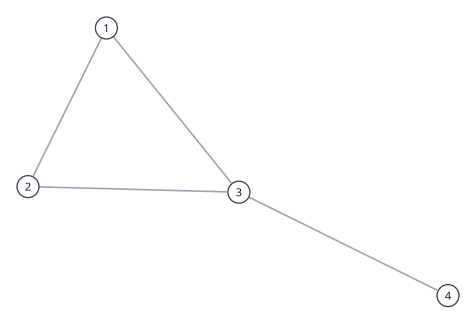

> 4 vertices, 4 edges

In [1]:
G = graph([1 2; 2 3; 3 1; 3 4])

Galileo prints the graph as the command that rebuilds it, and in a notebook also draws it. `order` counts the
vertices and `size` the edges; `vertices` and `edges` list them:

In [2]:
order(G)
size(G)
vertices(G)
neighbors(G, 3)

4

> the number of vertices

4

> the number of edges

{1, 2, 3, 4}

> 4 vertices

{1, 2, 4}

> the 3 vertices joined to 3

Vertices can have names. A third column gives each edge a **weight**, such as a distance in kilometres; we will use
weights in the next lesson.

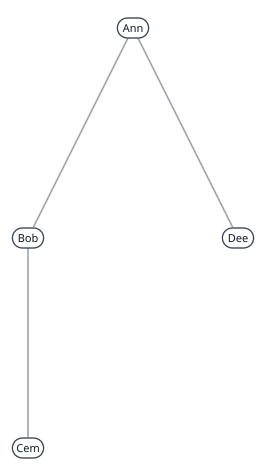

> 4 vertices, 3 edges

In [3]:
H = graph(["Ann" "Bob"; "Bob" "Cem"; "Ann" "Dee"])

Galileo also knows many graphs by name: `complete(n)` joins every pair, `cycle(n)` is a ring, `path(n)` a line,
`grid(m, n)` a lattice, `hypercube(d)` the corners and edges of a $d$-dimensional cube, and `petersen()` a famous
graph with 10 vertices that is a counterexample to many hopeful conjectures.

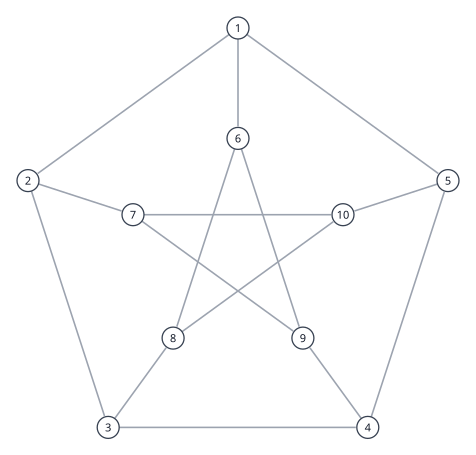

> the Petersen graph: 10 vertices, 15 edges, every vertex of degree 3; a five-pointed star inside a pentagon

In [4]:
petersen()

**Try this.** Draw `complete(5)`, `cycle(6)` and `grid(3, 4)`. How many edges does `complete(n)` have? Check your
formula with `size(complete(10))`.

## 2. Degrees and the handshake lemma

The **degree** of a vertex is the number of edges at it. `degree(G)` gives all of them as a row:

In [5]:
degree(G)
sum(degree(G))

[2, 2, 3, 1]

> the degrees add up to 8 = 2 × 4 edges, since each edge has two ends

8

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

The degrees add up to 8, twice the number of edges. That is no accident: every edge has two ends, so it adds 1 to
the degree of each of them. This is the **handshake lemma**:

$$\sum_{v} \deg(v) = 2\,|E|.$$

A consequence: the number of vertices of odd degree is always even, because the sum of all degrees is even. At a
party, the number of people who shook an odd number of hands is even.

In [6]:
degree(petersen())

[3, 3, 3, 3, 3, 3, 3, 3, 3, 3]

> the degrees add up to 30 = 2 × 15 edges, since each edge has two ends

Every vertex of the Petersen graph has degree 3; such a graph is called **3-regular**. With 10 vertices, the lemma
gives $10 \cdot 3 / 2 = 15$ edges.

**Try this.** Is there a graph with 7 vertices, each of degree 3? Use the handshake lemma before you try to draw one.

## 3. Counting walks with the adjacency matrix

The **adjacency matrix** $A$ has a 1 in row $i$, column $j$ when vertices $i$ and $j$ are joined, and 0 otherwise:

In [7]:
A = adjacency(G)

[0, 1, 1, 0;
 1, 0, 1, 0;
 1, 1, 0, 1;
 0, 0, 1, 0]

> entry (i, j) is 1 when vertices i and j are joined (the weight for a weighted graph); entry (i, j) of A^k counts the walks of length k from i to j

Matrix multiplication counts walks. Entry $(i, j)$ of $A^2$ is $\sum_k A_{ik} A_{kj}$: each $k$ with $i - k - j$ adds
1, so it counts the walks of length 2 from $i$ to $j$. In general $A^k$ counts walks of length $k$.

In [8]:
simplify(A^2)
simplify(A^3)

[2, 1, 1, 1;
 1, 2, 1, 1;
 1, 1, 3, 0;
 1, 1, 0, 1]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

[2, 3, 4, 1;
 3, 2, 4, 1;
 4, 4, 2, 3;
 1, 1, 3, 0]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

The diagonal of $A^2$ is the degree of each vertex (go out along an edge and come straight back). The diagonal of
$A^3$ counts closed walks of length 3: around the triangle 1, 2, 3 in either direction, so 2 at each of its corners
and 0 at vertex 4. The trace of $A^3$ is 6 times the number of triangles.

In [9]:
simplify(trace(A^3) / 6)

1

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

**Try this.** How many triangles does `complete(5)` have? Compute `trace(adjacency(complete(5))^3) / 6` and compare
with the number of ways to choose 3 vertices out of 5.

## 4. Euler's answer for Königsberg

The city had four pieces of land: the north bank N, the south bank S, the island K (Kneiphof) and the eastern part E.
Two bridges joined N to K, two joined S to K, and one each joined N to E, S to E and K to E. Galileo's graphs have at
most one edge between two vertices, so we put a point in the middle of each bridge, $b_1, \dots, b_7$. That does not
change the puzzle: crossing a bridge means walking land, bridge point, land.

In [10]:
K = graph(["N" "b1"; "b1" "K"; "N" "b2"; "b2" "K"; "S" "b3"; "b3" "K"; "S" "b4"; "b4" "K"; "N" "b5"; "b5" "E"; "S" "b6"; "b6" "E"; "K" "b7"; "b7" "E"]);
degree(K)

[3, 2, 5, 2, 3, 2, 2, 2, 3, 2, 2]

> the degrees add up to 28 = 2 × 14 edges, since each edge has two ends

The land masses have degrees 3, 5, 3 and 3 (N, K, S and E; the bridge points have degree 2). Euler's argument: every
time a walk passes through a piece of land it arrives on one bridge and leaves on another, using up two bridges. So
any land that is neither the start nor the end of the walk must have even degree. At most two vertices may have odd
degree, and here four do. No such walk exists:

In [11]:
eulerian(K)

false

> no walk uses every edge once: 4 vertices have odd degree ({"N", "K", "S", "E"}), and at most 2 may

Euler also showed the converse: a connected graph in which every vertex has even degree has a closed walk through
every edge exactly once (an **Euler circuit**), and one with exactly two odd vertices has an **Euler trail** from one
to the other. `eulerian` finds it with Hierholzer's method, which glues small loops together:

In [12]:
eulerian(complete(5))

{1, 2, 3, 1, 4, 2, 5, 3, 4, 5, 1}

> an Euler circuit: every edge once, back to the start (every vertex has even degree)

Every vertex of `complete(5)` has degree 4, so the circuit exists; it uses all 10 edges and comes back to 1. Draw it
on the graph:

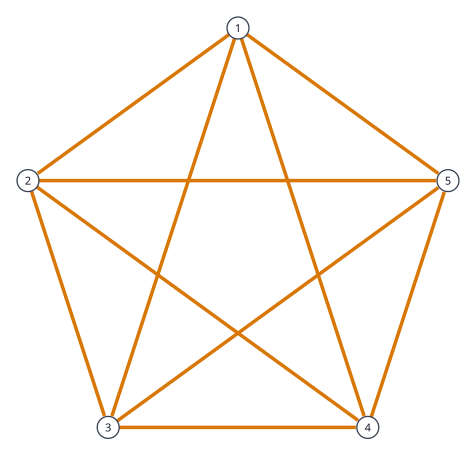

> 10 edges marked in orange

In [13]:
draw(complete(5), eulerian(complete(5)))

**Try this.** Königsberg later built new bridges. Add one more bridge from N to S (a point `b8` with edges N-b8 and
b8-S). Now which land masses have odd degree, and does `eulerian` find a walk? Where must it start and end?

## 5. Hamilton's puzzle: every vertex once

A different question sounds almost the same: is there a cycle that visits every **vertex** exactly once? William
Rowan Hamilton sold it as a game in 1857, on the corners of a dodecahedron. For Euler's question degrees decide
everything; for Hamilton's question no such simple test is known, and the problem is NP-complete. Galileo tries all
possibilities cleverly (dynamic programming over sets of vertices), which works up to about 20 vertices.

In [14]:
hamiltonian(hypercube(3))
hamiltonian(petersen())

{1, 2, 4, 3, 7, 8, 6, 5, 1}

> a cycle through every vertex exactly once, back to the start

false

> no cycle passes through every vertex exactly once (checked over all subsets of vertices)

The cube has such a cycle (a Gray code: neighbouring corners differ in one coordinate). The Petersen graph has none,
although every vertex has degree 3 and it looks very symmetric.

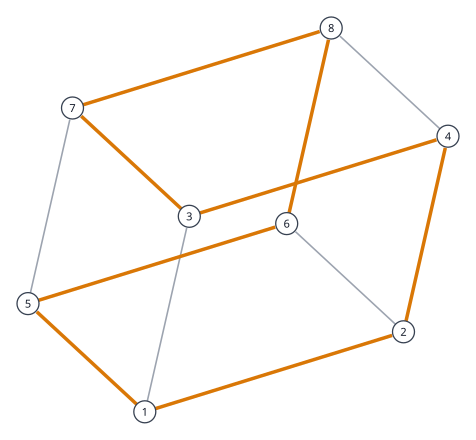

> 8 edges marked in orange

In [15]:
draw(hypercube(3), hamiltonian(hypercube(3)))

**Try this.** Does `grid(3, 3)` have a Hamiltonian cycle? Colour the grid like a chessboard: a cycle alternates
between black and white squares, so it has as many of each. Count them.

## 6. Connected and bipartite graphs

A graph is **connected** when every vertex can reach every other. `components` lists the pieces:

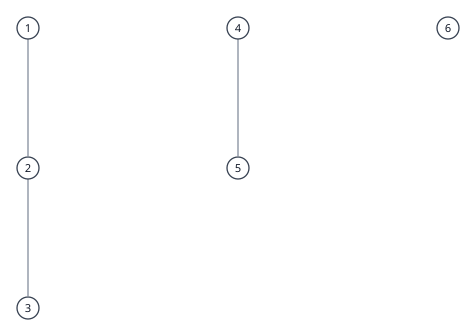

> 6 vertices, 3 edges

false

> 3 components

{{1, 2, 3}, {4, 5}, {6}}

> 3 connected components

In [16]:
C = graph([1 2; 2 3; 4 5], 6)
isconnected(C)
components(C)

A graph is **bipartite** when its vertices split into two sides with every edge going across, like jobs and
applicants, or the black and white squares of a chessboard. The test is simple: a graph is bipartite exactly when it
has no cycle of odd length. Galileo two-colours the graph by breadth-first search and reports the sides in its note:

In [17]:
isbipartite(grid(3, 3))
isbipartite(cycle(5))

true

> every edge joins {1, 3, 5, 7, 9} to {2, 4, 6, 8}

false

> not bipartite: the graph has a cycle of odd length

**Try this.** Is `hypercube(4)` bipartite? Think of the number of 1-bits of each corner.

## Summary

* A graph is vertices and edges; `graph([u v; ...])` builds one, a third column adds weights.
* Handshake lemma: the degrees add up to twice the number of edges, so odd vertices come in pairs.
* $A^k$ counts walks of length $k$; the trace of $A^3$ is 6 times the number of triangles.
* An Euler circuit exists exactly when the graph is connected and all degrees are even (a trail: two odd vertices).
* A Hamiltonian cycle visits every vertex once; no simple test is known.
* A graph is bipartite exactly when it has no odd cycle.

Next: [paths, trees and flows](02-paths-trees-and-flows.ipynb).

## Exercises

1. **Handshakes.** Seven people at a party each shake hands with exactly three others. Is that possible?
2. **Envelope.** The "house" drawing `graph([1 2; 2 3; 3 4; 4 1; 1 3; 2 4; 3 5; 4 5])` (a square with both
   diagonals and a roof). Can you draw it without lifting your pen? Where must you start?
3. **Walks.** In `cycle(6)`, how many walks of length 4 lead from vertex 1 back to itself? Use the adjacency matrix,
   then explain the number by listing step patterns (left or right four times).
4. **Cubes.** How many edges does `hypercube(d)` have? Use the handshake lemma, then check $d = 1, \dots, 6$.
5. **Petersen.** Show that the Petersen graph has no triangles and no 4-cycles: compute `trace(A^3)` and the
   diagonal of `A^4`, and compare with what the 3-regular structure alone would give.

## Hints and answers

* **Section 1, Try this.** `complete(n)` has $n(n - 1)/2$ edges; `size(complete(10))` is 45.
* **Section 2, Try this.** No: $7 \cdot 3 = 21$ is odd, but the degrees must add up to an even number.
* **Section 3, Try this.** 10, the same as $\binom{5}{3}$: any 3 vertices of a complete graph form a triangle.
* **Section 4, Try this.** N and S now have even degree (4 and 4); K and E stay odd (5 and 3), so an Euler trail
  exists from K to E (or back).
* **Section 5, Try this.** No. The grid has 5 squares of one colour and 4 of the other, so a cycle through all 9
  cannot alternate; `hamiltonian(grid(3, 3))` gives false.
* **Section 6, Try this.** Yes: every edge changes one bit, so it joins a corner with an even number of 1-bits to
  one with an odd number.
* **Exercise 1.** No, by the handshake lemma (21 is odd).
* **Exercise 2.** Yes. The degrees are 3, 3, 4, 4, 2: vertices 1 and 2 are odd, so start at one of them and end at
  the other; `eulerian` gives the trail 1, 2, 3, 1, 4, 3, 5, 4, 2.
* **Exercise 3.** 6: choose 2 of the 4 steps to go left, $\binom{4}{2} = 6$; it is entry $(1, 1)$ of $A^4$.
* **Exercise 4.** $d \cdot 2^d / 2 = d\,2^{d-1}$ edges: 1, 4, 12, 32, 80, 192.
* **Exercise 5.** `trace(A^3)` is 0, so there are no triangles. Each diagonal entry of $A^4$ is 15. Closed walks of
  length 4 that only go out and back are of two kinds: out and back twice ($3 \cdot 3 = 9$) or two steps out and two
  back ($3 \cdot 2 = 6$). That makes 15, so no walk goes round a 4-cycle.

## Sources

1. L. Euler, "Solutio problematis ad geometriam situs pertinentis", *Commentarii academiae scientiarum
   Petropolitanae* 8 (1741) 128–140 (written 1736).
2. N. L. Biggs, E. K. Lloyd and R. J. Wilson, *Graph Theory 1736–1936*, Oxford University Press (1976), chapters 1
   and 2.
3. R. J. Wilson, *Introduction to Graph Theory*, 5th ed., Pearson (2010), chapters 1 to 3.
4. D. A. Holton and J. Sheehan, *The Petersen Graph*, Cambridge University Press (1993).